# XGBoost

**Gradient boosting** builds a model from many small trees, each one fixing the mistakes of the trees before it. **XGBoost** is a fast, well-tuned library for it. The lesson page shows a simplified version; this notebook uses the real library.

This notebook goes with the **XGBoost** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

Each row is a tumour sample from a breast biopsy. The columns are eight measurements of the cell nuclei (size, texture, shape). The goal: predict whether the sample is **malignant** (`diagnosis = 1`) or **benign** (`0`).

The data is the Breast Cancer Wisconsin (Diagnostic) data set from the UCI repository (CC BY 4.0), reduced to eight columns. This is a teaching example, not medical advice.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/breast_cancer.csv"
dataset = pd.read_csv(DATA_URL)
X = dataset.drop(columns="diagnosis")
y = dataset["diagnosis"]
print(dataset.shape)
dataset.head()

(569, 9)


,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430


## 2. Split the data

We need three parts: training data, a **validation** set that decides when to stop, and a final test set.

In [2]:
from sklearn.model_selection import train_test_split

X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=0, stratify=y_rest)
print(len(X_train), len(X_val), len(X_test))

341 114 114


## 3. Train with early stopping

- `n_estimators` is the maximum number of rounds (trees).
- `learning_rate` is how big a step each tree takes.
- `max_depth` is how deep each tree may grow.
- `early_stopping_rounds=10` stops when the validation loss has not improved for 10 rounds.

In [3]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300, learning_rate=0.1, max_depth=3,
    eval_metric="logloss", early_stopping_rounds=10, random_state=0,
)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
print("best round:", model.best_iteration)
print(f"test accuracy: {model.score(X_test, y_test):.3f}")

best round: 69
test accuracy: 0.939


## 4. Plot the curves

The training loss keeps falling. The validation loss stops improving. That is the picture behind early stopping.

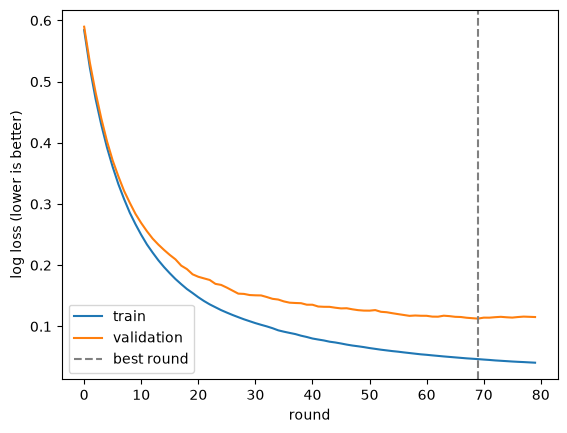

In [4]:
import matplotlib.pyplot as plt

hist = model.evals_result()
plt.plot(hist["validation_0"]["logloss"], label="train")
plt.plot(hist["validation_1"]["logloss"], label="validation")
plt.axvline(model.best_iteration, color="grey", linestyle="--", label="best round")
plt.xlabel("round")
plt.ylabel("log loss (lower is better)")
plt.legend()
plt.show()

## 5. Which measurements matter?

In [5]:
pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

mean_concave_points    0.519036
mean_area              0.136038
mean_perimeter         0.125936
mean_texture           0.063703
mean_radius            0.051837
mean_concavity         0.040747
mean_smoothness        0.036765
mean_compactness       0.025937
dtype: float32

## 6. Tune it with cross-validation

Combine this lesson with the last two: a small grid search over the learning rate and the depth.

In [6]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    XGBClassifier(n_estimators=100, random_state=0),
    {"learning_rate": [0.05, 0.1, 0.3], "max_depth": [2, 3, 5]},
    cv=5,
)
search.fit(X_rest, y_rest)
print(search.best_params_, round(search.best_score_, 3))

{'learning_rate': 0.05, 'max_depth': 2} 0.941


## 7. Try it yourself

- Set `learning_rate=1.0`. Does the validation loss get worse sooner?
- Set `max_depth=8`. What happens to the gap between train and validation?

## See it: the score after each boosting round

Each round adds one small tree. **Left:** log loss (lower is better) on the training, validation and test sets. **Right:** accuracy after each round. **Notice how** the training score keeps improving while the validation and test scores flatten out. The dashed line marks the round where early stopping chose to stop.

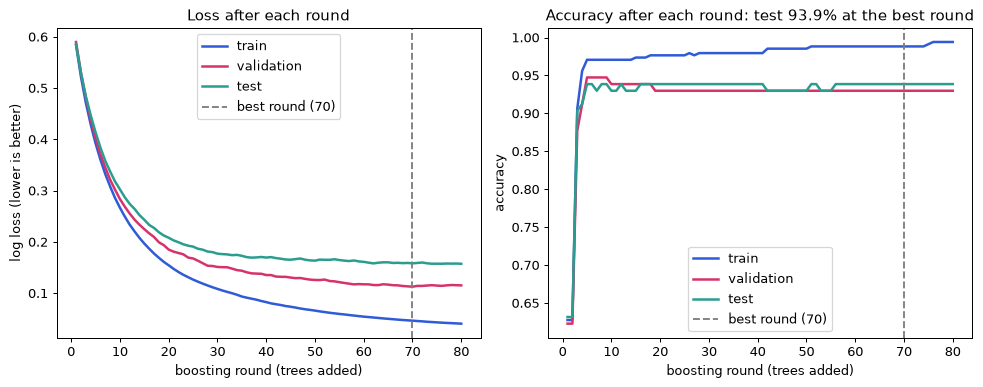

In [7]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

n_rounds = len(model.evals_result()['validation_0']['logloss'])
best = model.best_iteration
sets = {'train': (X_train, y_train), 'validation': (X_val, y_val), 'test': (X_test, y_test)}
colors = {'train': BLUE, 'validation': PINK, 'test': '#2a9d8f'}
loss = {k: [] for k in sets}
acc = {k: [] for k in sets}
for r in range(1, n_rounds + 1):
    for k, (Xs, ys) in sets.items():
        proba = model.predict_proba(Xs, iteration_range=(0, r))
        loss[k].append(log_loss(ys, proba))
        acc[k].append((proba.argmax(axis=1) == np.asarray(ys)).mean())

rounds = np.arange(1, n_rounds + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for k in sets:
    axes[0].plot(rounds, loss[k], color=colors[k], label=k, linewidth=2)
    axes[1].plot(rounds, acc[k], color=colors[k], label=k, linewidth=2)
for ax in axes:
    ax.axvline(best + 1, color='grey', linestyle='--', label=f'best round ({best + 1})')
    ax.set_xlabel('boosting round (trees added)')
    ax.legend()
axes[0].set_ylabel('log loss (lower is better)')
axes[0].set_title('Loss after each round')
axes[1].set_ylabel('accuracy')
axes[1].set_title(f"Accuracy after each round: test {acc['test'][best]:.1%} at the best round")
fig.tight_layout()
plt.show()
